<b>DV Experiment 3: Creating Bar and Line Charts for Series Data</b><br><br><b>Aim:</b> Create labeled sub-category bar charts and multi-series monthly line charts split by customer loyalty tier with custom hover tooltips.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

orders_df = pd.read_csv(os.path.join(data_dir, "superstore_sample.csv"))
cust_df = pd.read_csv(os.path.join(data_dir, "Dim_Customer.csv"))
df = orders_df.merge(cust_df, on="Customer_ID", how="left")

In [3]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

sub_agg = (
    df.groupby("Sub_Category", as_index=False)[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=True)
)
sub_agg["Profit_Margin_Pct"] = (sub_agg["Profit"] / sub_agg["Sales"] * 100.0).round(2)

tier_monthly = (
    df.groupby(["Year_Month", "Loyalty_Tier"], as_index=False)["Sales"]
    .sum()
    .sort_values("Year_Month")
)

print("Sub-Category Series Summary:")
print(sub_agg.sort_values("Sales", ascending=False).round(2).to_string(index=False))

Sub-Category Series Summary:
Sub_Category     Sales   Profit  Profit_Margin_Pct
     Laptops 192874.78 23399.97              12.13
      Phones  95686.18 16721.48              17.48
      Tables  69239.37  5608.77               8.10
   Bookcases  60615.71  5204.76               8.59
      Chairs  55962.19  7789.48              13.92
     Storage  37790.67  6213.44              16.44
 Accessories  20430.30  5572.24              27.27
     Binders  11498.00  2879.86              25.05
       Paper   9806.00  3106.65              31.68


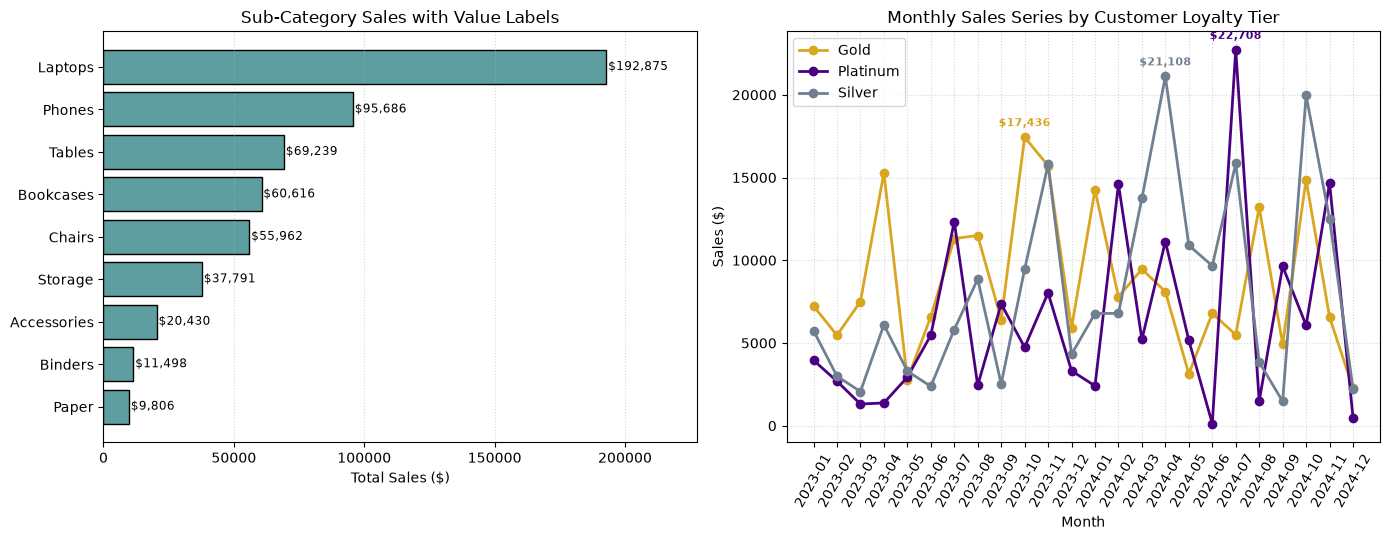

Interactive HTML saved to: outputs\DV_Exp3_Interactive_Series.html


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

bars = ax[0].barh(sub_agg["Sub_Category"], sub_agg["Sales"], color="cadetblue", edgecolor="black")
for bar in bars:
    w = bar.get_width()
    ax[0].text(w + 700, bar.get_y() + bar.get_height() / 2.0, f"${w:,.0f}", va="center", fontsize=8.5)
ax[0].set_xlim(0, sub_agg["Sales"].max() * 1.18)
ax[0].set_title("Sub-Category Sales with Value Labels")
ax[0].set_xlabel("Total Sales ($)")
ax[0].grid(True, axis="x", linestyle=":", alpha=0.5)

tier_colors = {"Platinum": "indigo", "Gold": "goldenrod", "Silver": "slategray"}
for tier in sorted(tier_monthly["Loyalty_Tier"].unique()):
    sub = tier_monthly[tier_monthly["Loyalty_Tier"] == tier]
    ax[1].plot(sub["Year_Month"], sub["Sales"], marker="o", linewidth=2, label=tier, color=tier_colors[tier])
    peak = sub.loc[sub["Sales"].idxmax()]
    ax[1].annotate(
        f"${peak['Sales']:,.0f}",
        xy=(peak["Year_Month"], peak["Sales"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
        color=tier_colors[tier],
    )

ax[1].set_title("Monthly Sales Series by Customer Loyalty Tier")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Sales ($)")
ax[1].tick_params(axis="x", rotation=60)
ax[1].legend()
ax[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

interactive_fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Sub-Category Sales & Margin (Tooltips)", "Monthly Sales by Loyalty Tier"),
)

interactive_fig.add_trace(
    go.Bar(
        y=sub_agg["Sub_Category"],
        x=sub_agg["Sales"],
        orientation="h",
        marker_color="cadetblue",
        text=sub_agg["Sales"].map(lambda v: f"${v:,.0f}"),
        textposition="outside",
        customdata=sub_agg[["Profit", "Profit_Margin_Pct"]],
        hovertemplate="<b>%{y}</b><br>Sales: $%{x:,.2f}<br>Profit: $%{customdata[0]:,.2f}<br>Margin: %{customdata[1]:.2f}%<extra></extra>",
        name="Sub-Category Sales",
    ),
    row=1,
    col=1,
)

for tier in sorted(tier_monthly["Loyalty_Tier"].unique()):
    sub = tier_monthly[tier_monthly["Loyalty_Tier"] == tier]
    interactive_fig.add_trace(
        go.Scatter(
            x=sub["Year_Month"],
            y=sub["Sales"],
            mode="lines+markers",
            name=tier,
            line=dict(color=tier_colors[tier], width=2.4),
            hovertemplate="<b>" + tier + "</b><br>Month: %{x}<br>Sales: $%{y:,.2f}<extra></extra>",
        ),
        row=1,
        col=2,
    )

interactive_fig.update_layout(height=520, width=1160, title_text="Bar and Line Charts for Series Data")
html_path = os.path.join(out_dir, "DV_Exp3_Interactive_Series.html")
interactive_fig.write_html(html_path, include_plotlyjs="cdn")
print("Interactive HTML saved to:", html_path)

<b>Observation:</b> Direct bar labels and interactive tooltip metadata clearly communicate profit margins and seasonal spikes across loyalty tiers.